# Акцепторы и доноры водородной связи: простой анализ

Мы изучаем две характеристики каждой молекулы из базы DrugBank:

- **A** (`cal_h_bond_acceptor_count`) — сколько в молекуле мест, которые могут **принимать** водородную связь;
- **D** (`cal_h_bond_donor_count`) — сколько мест, которые могут её **отдавать**.

Это обычные целые числа (0, 1, 2, ...). Идём по плану из `data_review.ipynb`, после каждого шага — вывод «простыми словами».

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)
sys.path.insert(0, str(project_root))

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

RNG = np.random.default_rng(42)   # чтобы результаты повторялись

df = pd.read_csv(project_root / "cleaned_data.csv")
a = df["cal_h_bond_acceptor_count"].astype(int).to_numpy()
d = df["cal_h_bond_donor_count"].astype(int).to_numpy()
N = len(df)
print(f"Молекул в данных: {N}, пропусков в A и D нет")

Молекул в данных: 10046, пропусков в A и D нет


## Шаг 1. Почему A и D — случайные величины

Представим, что мы берём из базы **случайную молекулу** и смотрим на её A и D. Заранее мы не знаем, что получится: молекулы очень разные, поэтому числа от выбора к выбору меняются. Именно это и значит «случайная величина». График ниже показывает, как часто встречается каждое значение.

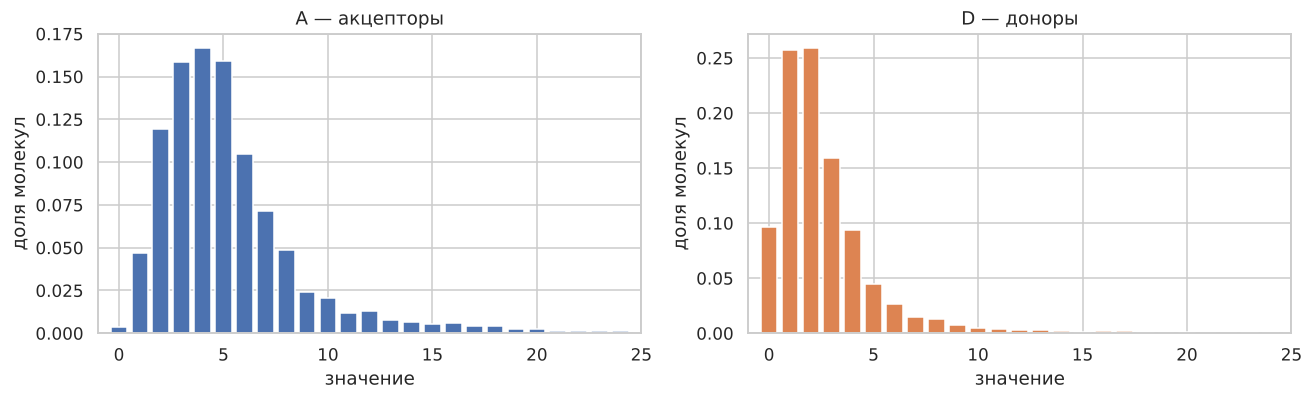

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, x, name, color in zip(axes, (a, d), ("A — акцепторы", "D — доноры"), ("C0", "C1")):
    values, counts = np.unique(x, return_counts=True)
    ax.bar(values, counts / N, color=color)
    ax.set_title(name); ax.set_xlabel("значение"); ax.set_ylabel("доля молекул"); ax.set_xlim(-1, 25)
plt.tight_layout()

**Простыми словами:** чаще всего у молекулы 3–6 акцепторов и 1–3 донора, но есть и редкие молекулы, у которых этих мест десятки. Поэтому «хвост» справа длинный.

## Шаг 2. Связаны ли A и D между собой

Проверим это двумя числами — коэффициентами корреляции (от −1 до 1, чем ближе к ±1, тем сильнее связь):

- **Пирсон** ищет прямолинейную связь и сильно реагирует на редкие огромные значения;
- **Спирмен** смотрит только на порядок значений, поэтому к огромным значениям устойчив.

Гипотеза проверки: $H_0$ — «A и D не связаны». Если p-value меньше 0,05, считаем, что связь не случайна.

Пирсон (все данные):             0.85
Пирсон (без самых больших 1%):   0.77
Спирмен:                         0.65   (p-value меньше 1e-300, то есть практически 0)


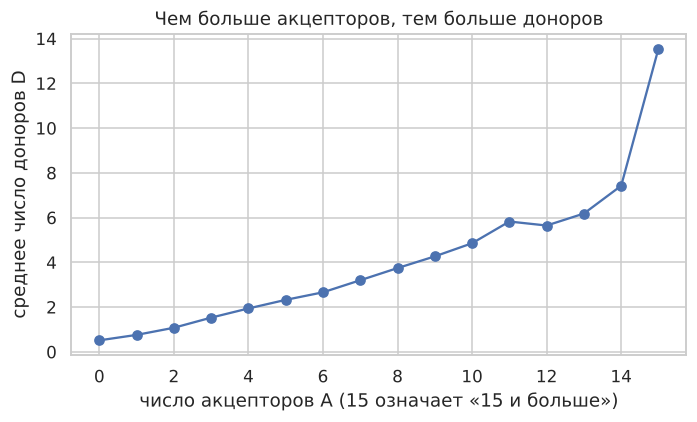

In [3]:
pearson = stats.pearsonr(a, d).statistic
spearman = stats.spearmanr(a, d)
core = (a <= np.percentile(a, 99)) & (d <= np.percentile(d, 99))   # без самых больших 1% молекул
pearson_core = stats.pearsonr(a[core], d[core]).statistic

print(f"Пирсон (все данные):             {pearson:.2f}")
print(f"Пирсон (без самых больших 1%):   {pearson_core:.2f}")
p_text = "меньше 1e-300, то есть практически 0" if spearman.pvalue < 1e-300 else f"{spearman.pvalue:.1e}"
print(f"Спирмен:                         {spearman.statistic:.2f}   (p-value {p_text})")

# наглядно: сколько доноров в среднем у молекул с данным числом акцепторов
a_cut = np.minimum(a, 15)
mean_d = pd.Series(d).groupby(a_cut).mean()
plt.figure(figsize=(6.5, 4))
plt.plot(mean_d.index, mean_d.values, "o-")
plt.xlabel("число акцепторов A (15 означает «15 и больше»)")
plt.ylabel("среднее число доноров D")
plt.title("Чем больше акцепторов, тем больше доноров")
plt.tight_layout()

**Простыми словами:** A и D действительно связаны — чем больше у молекулы акцепторов, тем в среднем больше доноров (p-value практически ноль, значит, это не случайность). Но число 0,85 из корреляционной матрицы немного завышено: его подтягивают редкие очень большие молекулы. Без них оно 0,77, а по Спирмену 0,65. Связь сильная, но не «один в один».

## Шаг 3. Хватает ли данных: сходятся ли оценки к «правде»

Возьмём «правду» — среднее и корреляцию по **всей** базе. Теперь будем брать случайные выборки разного размера (по 300 выборок каждого размера) и смотреть, насколько оценки по ним отличаются от «правды». Если оценка хорошая, то чем больше выборка, тем кучнее она ложится вокруг правильного значения. Это и называется **состоятельностью**.

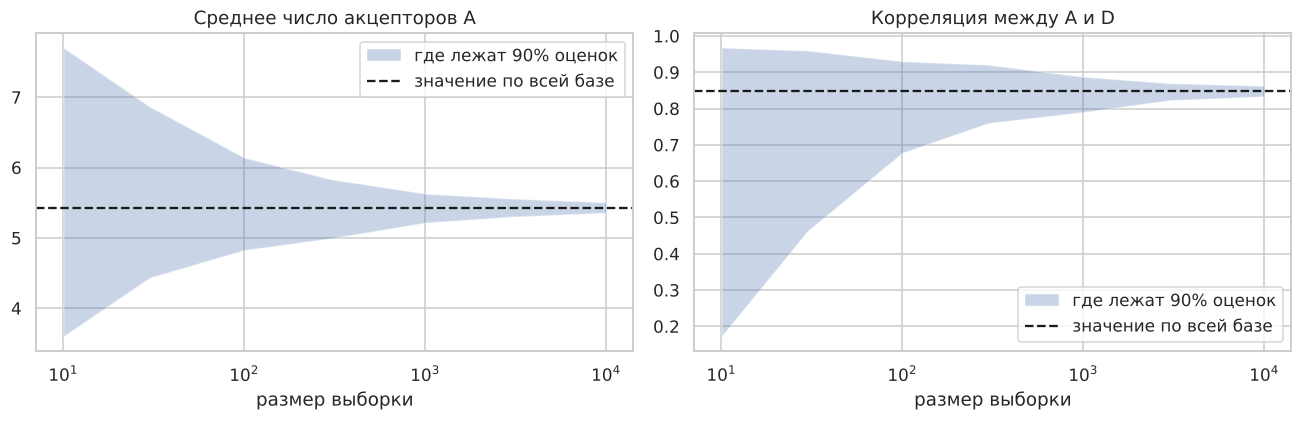

,разброс оценок среднего A,разброс оценок корреляции
размер выборки,,
10,1.279,0.242
30,0.759,0.153
100,0.414,0.078
300,0.259,0.051
1000,0.128,0.029
3000,0.075,0.014
10000,0.044,0.009


In [4]:
sizes = [10, 30, 100, 300, 1000, 3000, 10000]
repeats = 300
true_mean, true_corr = a.mean(), np.corrcoef(a, d)[0, 1]

means, corrs = {}, {}
for n in sizes:
    idx = RNG.integers(0, N, size=(repeats, n))
    A_s, D_s = a[idx], d[idx]
    means[n] = A_s.mean(axis=1)
    Ac, Dc = A_s - A_s.mean(1, keepdims=True), D_s - D_s.mean(1, keepdims=True)
    corrs[n] = (Ac * Dc).sum(1) / np.sqrt((Ac ** 2).sum(1) * (Dc ** 2).sum(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, est, truth, title in ((axes[0], means, true_mean, "Среднее число акцепторов A"),
                              (axes[1], corrs, true_corr, "Корреляция между A и D")):
    lo = [np.percentile(est[n], 5) for n in sizes]
    hi = [np.percentile(est[n], 95) for n in sizes]
    ax.fill_between(sizes, lo, hi, alpha=0.3, label="где лежат 90% оценок")
    ax.axhline(truth, color="k", ls="--", label="значение по всей базе")
    ax.set_xscale("log"); ax.set_xlabel("размер выборки"); ax.set_title(title); ax.legend()
plt.tight_layout()

spread = pd.DataFrame({
    "разброс оценок среднего A": [means[n].std() for n in sizes],
    "разброс оценок корреляции": [corrs[n].std() for n in sizes],
}, index=pd.Index(sizes, name="размер выборки")).round(3)
spread

**Простыми словами:** чем больше выборка, тем уже «коридор» оценок и тем ближе он к настоящему значению. На 1000 молекул среднее уже определено довольно точно, на нескольких тысячах — очень точно. Значит, и среднее, и корреляция — надёжные оценки, а наших 10 тысяч молекул для них более чем достаточно.

## Шаг 4. Как выглядят данные и что с ними делать

Посмотрим на основные числа и на «выбросы» — необычно большие значения. Затем проверим, помогает ли логарифм сделать распределение более симметричным (асимметрия около 0 — значит, симметрично).

In [5]:
def summary(x):
    q1, q3 = np.percentile(x, [25, 75])
    border = q3 + 1.5 * (q3 - q1)
    return pd.Series({
        "минимум": x.min(), "медиана": np.median(x), "среднее": round(x.mean(), 2), "максимум": x.max(),
        "стандартное отклонение": round(x.std(ddof=1), 2),
        "асимметрия": round(stats.skew(x), 2),
        "асимметрия после ln(1+x)": round(stats.skew(np.log1p(x)), 2),
        "молекул-«выбросов»": int((x > border).sum()),
    })

pd.DataFrame({"A": summary(a), "D": summary(d)})

,A,D
минимум,0.00,0.00
медиана,5.00,2.00
среднее,5.43,2.74
максимум,79.00,60.00
стандартное отклонение,4.31,3.15
асимметрия,4.16,5.41
асимметрия после ln(1+x),0.34,0.34
молекул-«выбросов»,767.00,638.00


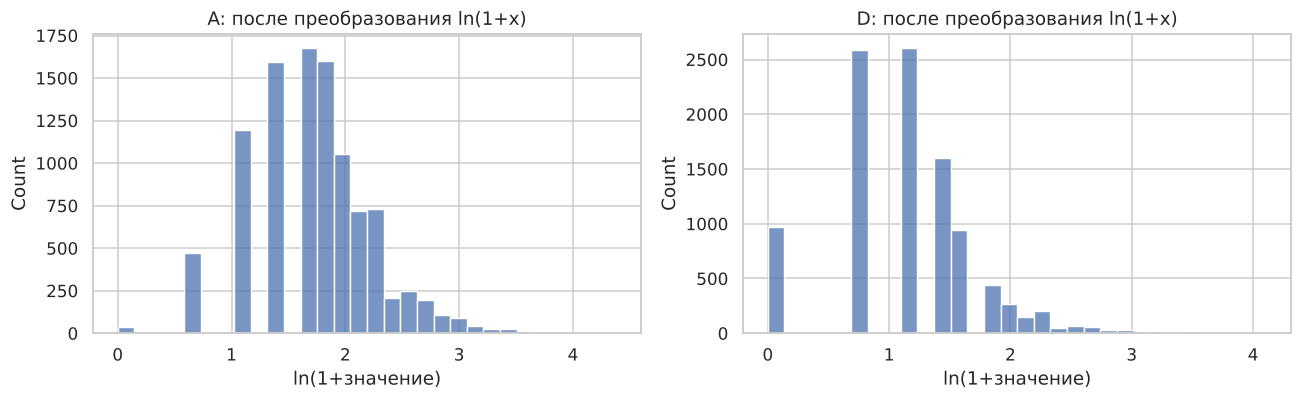

,name,cal_h_bond_acceptor_count,cal_h_bond_donor_count,cal_molecular_weight
4441,Delcasertib,79.0,55.0,2880.310
4314,Ularitide,63.0,60.0,3505.926
4809,DiaPep 277,60.0,33.0,2390.768
9696,Zilucoplan,59.0,28.0,3562.229
9312,Avexitide,53.0,45.0,3369.800


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, x, name in zip(axes, (a, d), ("A", "D")):
    sns.histplot(np.log1p(x), bins=30, ax=ax)
    ax.set_title(f"{name}: после преобразования ln(1+x)"); ax.set_xlabel("ln(1+значение)")
plt.tight_layout()
df.nlargest(5, "cal_h_bond_acceptor_count")[["name", "cal_h_bond_acceptor_count", "cal_h_bond_donor_count", "cal_molecular_weight"]]

**Простыми словами:** большинство значений маленькие, но есть редкие гигантские (до 79 акцепторов и 60 доноров). Это не ошибки: таблица показывает, что это очень тяжёлые молекулы (масса 2400–3600), поэтому удалять их не нужно. Логарифм делает распределение гораздо симметричнее (асимметрия падает с 4,16 до 0,34 у A и с 5,41 до 0,34 у D), поэтому для методов, которые любят «ровные» данные, лучше брать `ln(1+x)`.

## Шаг 5. Выборка «с возвращением» и «без возвращения»

- **С возвращением:** вытащили молекулу, записали, вернули обратно — она может попасться снова.
- **Без возвращения:** вытащили — и больше не кладём.

Сравним, насколько точно по таким выборкам определяется среднее A (по 500 повторов).

In [7]:
rows = []
for n in [100, 1000, 5000, 9000]:
    with_return = a[RNG.integers(0, N, size=(500, n))].mean(axis=1)
    without_return = np.array([a[RNG.choice(N, size=n, replace=False)].mean() for _ in range(500)])
    rows.append({"размер выборки": n,
                 "оценка среднего (с возвр.)": with_return.mean(),
                 "оценка среднего (без возвр.)": without_return.mean(),
                 "разброс оценок (с возвр.)": with_return.std(),
                 "разброс оценок (без возвр.)": without_return.std()})
print(f"Настоящее среднее A по всей базе: {a.mean():.3f}")
pd.DataFrame(rows).set_index("размер выборки").round(3)

Настоящее среднее A по всей базе: 5.428


,оценка среднего (с возвр.),оценка среднего (без возвр.),разброс оценок (с возвр.),разброс оценок (без возвр.)
размер выборки,,,,
100,5.422,5.411,0.440,0.419
1000,5.426,5.428,0.136,0.128
5000,5.428,5.428,0.060,0.041
9000,5.431,5.429,0.047,0.015


**Простыми словами:** оба способа дают правильное среднее. Разница только в точности: когда выборка мала по сравнению с базой, способы почти не отличаются, а когда мы берём почти всю базу, выборка «без возвращения» оказывается намного точнее (мы ведь почти пересчитали все молекулы), и разброс у неё почти исчезает.

## Шаг 6. Какое распределение подходит

Для «счётных» величин сначала пробуют **распределение Пуассона**. У него есть особенность: дисперсия (разброс) равна среднему. Проверим, так ли это у нас. Если разброс заметно больше, берут более гибкое **отрицательное биномиальное** распределение. Модели сравниваем по AIC — чем он **меньше**, тем лучше модель.

In [8]:
def fit_models(x):
    values, counts = np.unique(x, return_counts=True)
    lam = x.mean()
    ll_pois = (counts * stats.poisson.logpmf(values, lam)).sum()

    m, v = x.mean(), x.var(ddof=1)
    p0 = m / v; r0 = m * p0 / (1 - p0)
    sig = lambda t: 1 / (1 + np.exp(-t))
    nll = lambda t: -(counts * stats.nbinom.logpmf(values, np.exp(t[0]), sig(t[1]))).sum()
    res = minimize(nll, [np.log(r0), np.log(p0 / (1 - p0))], method="Nelder-Mead")
    r, p = np.exp(res.x[0]), sig(res.x[1])
    return lam, (r, p), 2 * 1 - 2 * ll_pois, 2 * 2 + 2 * res.fun

rows, fitted = [], {}
for name, x in (("A", a), ("D", d)):
    lam, (r, p), aic_p, aic_nb = fit_models(x)
    fitted[name] = (lam, r, p)
    rows.append({"величина": name, "среднее": x.mean(), "дисперсия": x.var(ddof=1),
                 "дисперсия / среднее": x.var(ddof=1) / x.mean(),
                 "AIC Пуассон": aic_p, "AIC отриц. биномиальное": aic_nb})
pd.DataFrame(rows).set_index("величина").round(2)

,среднее,дисперсия,дисперсия / среднее,AIC Пуассон,AIC отриц. биномиальное
величина,,,,,
A,5.43,18.59,3.42,58116.46,51387.39
D,2.74,9.90,3.62,48273.46,42289.71


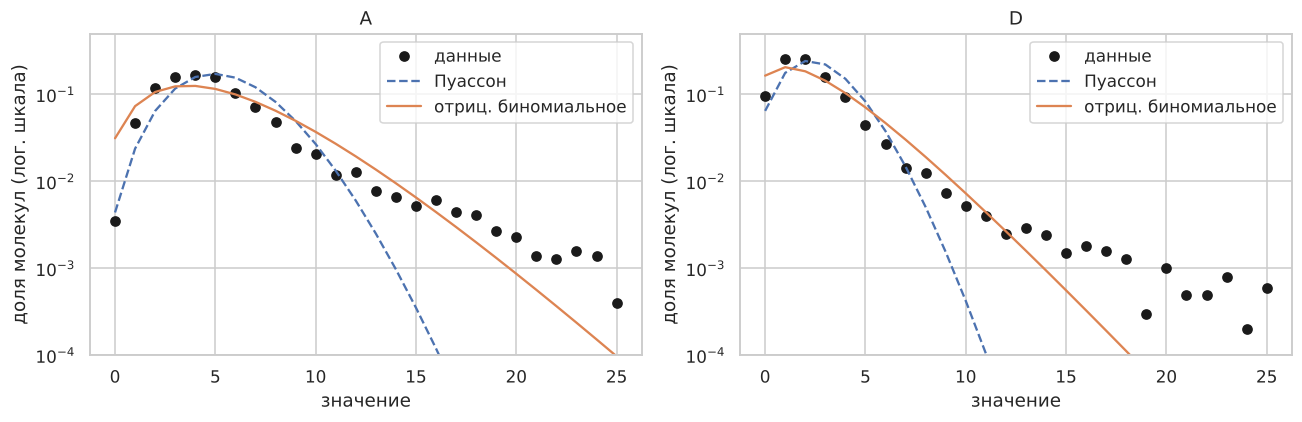

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ks = np.arange(0, 26)
for ax, (name, x) in zip(axes, (("A", a), ("D", d))):
    lam, r, p = fitted[name]
    ax.semilogy(ks, np.bincount(x, minlength=26)[:26] / N, "ko", label="данные")
    ax.semilogy(ks, stats.poisson.pmf(ks, lam), "--", label="Пуассон")
    ax.semilogy(ks, stats.nbinom.pmf(ks, r, p), "-", label="отриц. биномиальное")
    ax.set_ylim(1e-4, 0.5); ax.set_xlabel("значение"); ax.set_ylabel("доля молекул (лог. шкала)")
    ax.set_title(name); ax.legend()
plt.tight_layout()

**Простыми словами:** у обеих величин разброс в 3–4 раза больше среднего, поэтому Пуассон не подходит (на графике его линия резко обрывается там, где у данных ещё есть «хвост»). Отрицательное биномиальное распределение справляется заметно лучше (AIC меньше почти на 6 000–6 700), но тоже не идеально: хвост у настоящих данных всё равно тяжелее. Для практических целей его можно использовать как приближение; точнее модель можно сделать, если смешать два распределения (это сделано в расширенной версии анализа).

## Шаг 7. Проверка гипотез

**Гипотеза 1.** *Связано ли отсутствие значения `state` (физическое состояние вещества) с A и D?*
$H_0$: у молекул с пропущенным и известным `state` A (или D) распределены одинаково. Используем критерий Манна–Уитни; если p-value < 0,05, отвергаем $H_0$.

**Гипотеза 2.** *Можно ли заменять A на D (и наоборот)?* Связь мы уже доказали (шаг 2), но этого мало: надо проверить, насколько точно по одной величине угадывается другая.

In [10]:
# Гипотеза 1
missing = df["state"].isna().to_numpy()
rows = []
for name, x in (("A", a), ("D", d)):
    p = stats.mannwhitneyu(x[missing], x[~missing]).pvalue
    rows.append({"величина": name,
                 "медиана (state пропущен)": np.median(x[missing]),
                 "медиана (state известен)": np.median(x[~missing]),
                 "p-value": f"{p:.3g}",
                 "различие значимо": "да" if p < 0.05 else "нет"})
print("Гипотеза 1:")
pd.DataFrame(rows).set_index("величина")

Гипотеза 1:


,медиана (state пропущен),медиана (state известен),p-value,различие значимо
величина,,,,
A,5.0,4.0,1.14e-21,да
D,2.0,2.0,0.254,нет


In [11]:
# Гипотеза 2: насколько точно по одной величине угадывается другая
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

def check(x, y):
    pred = cross_val_predict(LinearRegression(), x.reshape(-1, 1), y, cv=KFold(5, shuffle=True, random_state=42))
    return {"средняя ошибка прогноза": np.abs(y - pred).mean(),
            "ошибка, если всегда называть медиану": np.abs(y - np.median(y)).mean(),
            "угадано с точностью ±1": (np.abs(np.round(pred) - y) <= 1).mean()}

print("Гипотеза 2:")
pd.DataFrame({"угадываем A по D": check(d, a), "угадываем D по A": check(a, d)}).T.round(2)

Гипотеза 2:


,средняя ошибка прогноза,"ошибка, если всегда называть медиану",угадано с точностью ±1
угадываем A по D,1.65,2.52,0.55
угадываем D по A,1.15,1.64,0.75


**Простыми словами:**

- **Гипотеза 1:** у A различие есть (молекулы без `state` в среднем имеют больше акцепторов), у D значимого различия нет. Раз различается хотя бы одна величина, пропуски в `state` не выглядят случайными. Дополнительная проверка в расширенной версии показала, что такие вещества в среднем тяжелее (масса 402 против 331).
- **Гипотеза 2:** по одной величине вторая угадывается лучше, чем «наугад», но ошибка в 1–2 штуки на молекулу остаётся (при типичных значениях A около 5 и D около 2 это много). Поэтому A и D связаны, но заменять одну другой нельзя без потери информации.

## Шаг 8. Итог

1. **Данные:** 10 046 молекул, пропусков нет. Типичные значения: A около 5, D около 2, у редких тяжёлых молекул намного больше.
2. **Связь:** A и D связаны положительно и надёжно (Спирмен 0,65; Пирсон 0,85, но он завышен из-за редких гигантов).
3. **Оценки:** среднее и корреляция по выборкам сходятся к значениям по всей базе, данных хватает с запасом.
4. **Форма данных:** сильно скошены вправо; логарифм `ln(1+x)` делает их почти симметричными. Выбросы — настоящие тяжёлые молекулы, оставляем.
5. **Выборки:** оба способа дают правильное среднее; без возвращения точнее, если берём большую часть базы.
6. **Распределение:** Пуассон не подходит (разброс в 3–4 раза больше среднего), отрицательное биномиальное лучше, но хвост описывает неидеально.
7. **Гипотезы:** пропуски в `state` не случайны; A нельзя просто заменить на D.

**Для следующего этапа (генератор):** так как A и D связаны, генерировать их надо не независимо, а вместе или D при заданном A.